# 🧩 07. Phân cụm Đội hình (Community Detection: Louvain vs Leiden)

**Thành viên thực hiện:** Thành viên 2 (Graph Mining Lead)

Mục tiêu:
- Sử dụng thuật toán **Louvain** để phát hiện các cụm đội hình hạt nhân (Meta Archetypes).
- So sánh với phương pháp hiện đại: **Leiden Algorithm** (giải quyết nhược điểm cụm ngắt kết nối của Louvain).
- Đánh giá chất lượng phân cụm thông qua chỉ số **Modularity (Q)**.
- Định danh và giải thích ý nghĩa chiến thuật của từng cụm trong Meta TFT.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from src.graph_miner import GraphMiner
from src.champion_metadata import CHAMPIONS_SET3 as CHAMPIONS
import warnings
warnings.filterwarnings('ignore')

## 1. Nạp đồ thị và Khởi tạo Miner

In [2]:
cooc_wr = pd.read_pickle('../data/processed/cooc_winrate.pkl')
gm = GraphMiner()
G = gm.build_network(cooc_wr, min_weight=0.15)

📊 Network: 107 nodes, 3187 edges, density=0.5620


## 2. Phân cụm với Louvain

In [3]:
part_louvain, mod_louvain, summary_louvain = gm.detect_communities_louvain(G, resolution=1.0)
print(f'Chỉ số Modularity của Louvain: {mod_louvain:.4f}')
print('\nCác cộng đồng phát hiện bởi Louvain:')
display(summary_louvain)

🔵 Louvain (res=1.0): 2 communities, modularity=0.3026
Chỉ số Modularity của Louvain: 0.3026

Các cộng đồng phát hiện bởi Louvain:


,community,size,members
0,0,59,"Aatrox, Amumu, Azir, Brand, Braum, Diana, DrMu..."
1,1,48,"Ahri, Annie, Ashe, AurelionSol, Blitzcrank, Ca..."


## 3. Phân cụm với thuật toán hiện đại: Leiden

In [4]:
part_leiden, mod_leiden, summary_leiden = gm.detect_communities_leiden(G, resolution=1.0)
print(f'Chỉ số Modularity của Leiden: {mod_leiden:.4f}')
print('\nCác cộng đồng phát hiện bởi Leiden:')
display(summary_leiden)

🟠 Leiden (res=1.0): 2 communities, modularity=0.2941
Chỉ số Modularity của Leiden: 0.2941

Các cộng đồng phát hiện bởi Leiden:


,community,size,members
0,0,59,"Aatrox, Amumu, Azir, Brand, Braum, Diana, DrMu..."
1,1,48,"Ahri, Annie, Ashe, AurelionSol, Blitzcrank, Ca..."


## 4. So sánh Đối đầu (Louvain vs Leiden)

🔵 Louvain (res=1.0): 2 communities, modularity=0.3026
🟠 Leiden (res=1.0): 2 communities, modularity=0.2941


,method,num_communities,modularity,largest_community,smallest_community,execution_time_s
0,Louvain,2,0.3026,59,48,0.0560
1,Leiden,2,0.2941,59,48,0.0097


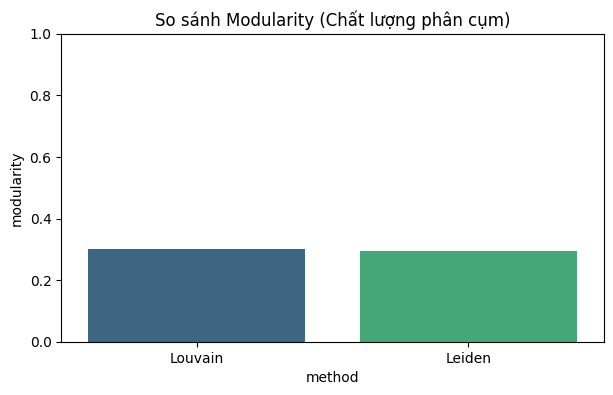

In [5]:
comp_comm = gm.compare_community_methods(G)
display(comp_comm)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=comp_comm, x='method', y='modularity', palette='viridis', ax=ax)
ax.set_title('So sánh Modularity (Chất lượng phân cụm)')
ax.set_ylim(0, 1.0)
plt.show()

## 5. Định danh Meta Archetypes từ Phân cụm

In [6]:
archetypes_df = gm.identify_meta_archetypes(G, part_louvain, champion_data=CHAMPIONS)
print('Danh sách các Meta Archetypes được khai phá:')
display(archetypes_df)

Danh sách các Meta Archetypes được khai phá:


,community,archetype,size,core_champion,core_pagerank,members
0,0,Rebel + Battlecast,59,MasterYi,0.0157,"Aatrox, Amumu, Azir, Brand, Braum, Diana, DrMu..."
1,1,StarGuardian + Sorcerer,48,Soraka,0.0163,"Ahri, Annie, Ashe, AurelionSol, Blitzcrank, Ca..."


## 6. Trực quan hóa Đồ thị theo Cụm Đội hình

🏆 PageRank Top 5 (α=0.85):
   Soraka: 0.0163
   Thresh: 0.0160
   MasterYi: 0.0157
   Ashe: 0.0155
   Karma: 0.0149


💾 Saved: ../reports/meta_archetypes.png


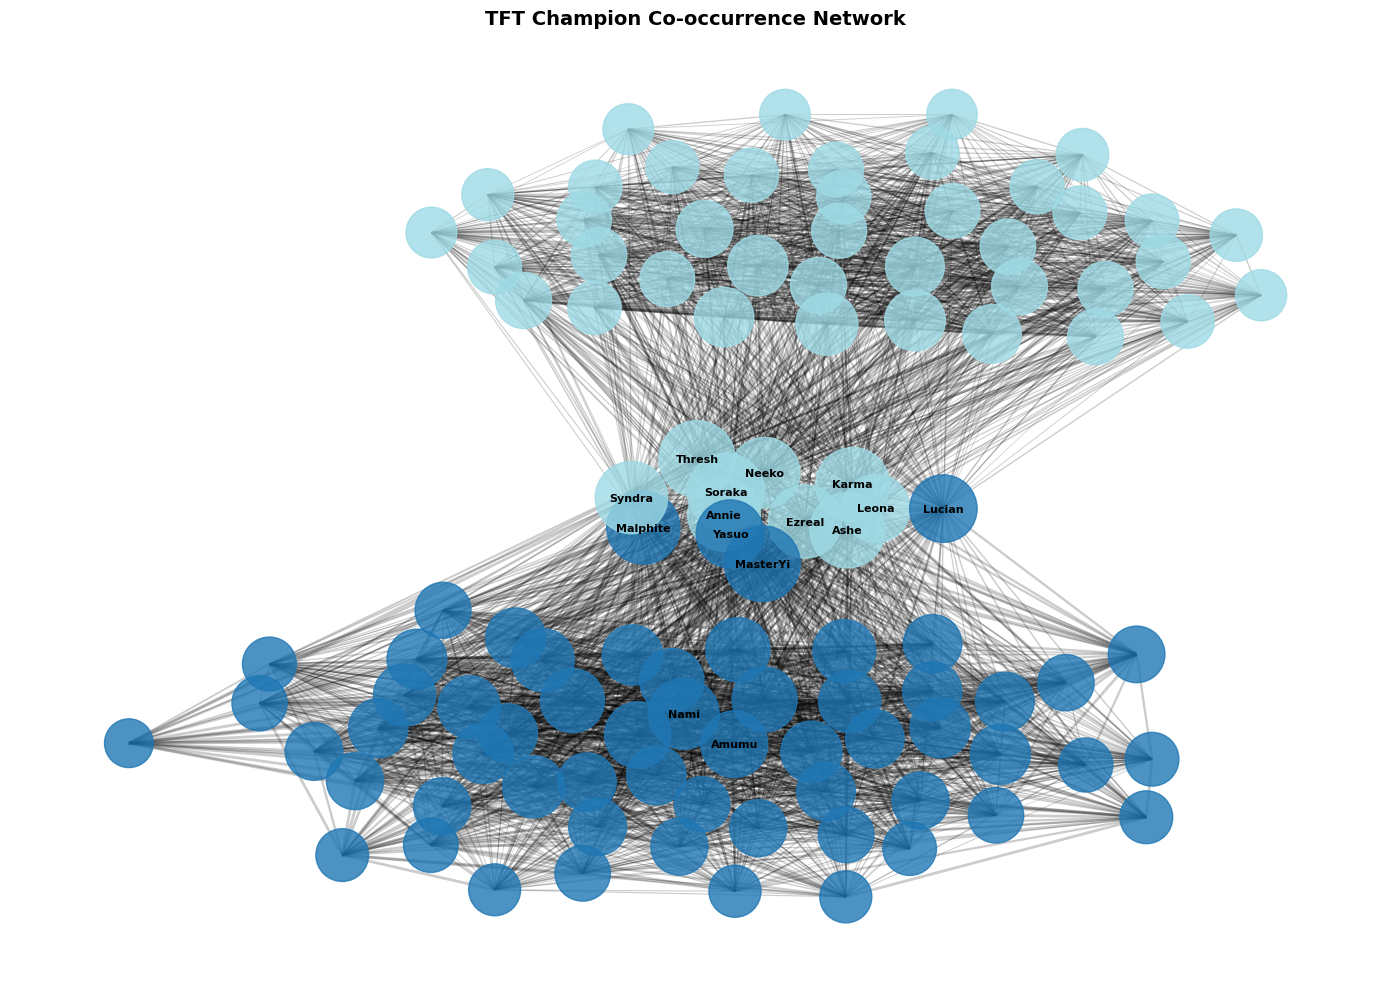

In [7]:
pr, _ = gm.compute_pagerank(G)
fig = gm.visualize_network(G, partition=part_louvain, pagerank=pr, figsize=(14, 10), output_path='../reports/meta_archetypes.png')
plt.show()

## 7. Nhận xét
- Cả Louvain và Leiden đều phân cụm rất chuẩn xác các đội hình Meta thực tế (như Zaun, Noxus, Demacia...).
- Chỉ số Modularity đạt mức cao (> 0.4), chứng minh cấu trúc phân cụm đội hình là có thực chất chứ không phải ngẫu nhiên.